# Modernized BEM for 2D Elastostatics (ELQUABE)

This notebook runs the complete pipeline for the modernized **ELQUABE** Fortran 90 program (originally developed by Brebbia & Dominguez in *Boundary Elements: An Introductory Course*):

1. **Modular Fortran 90 Architecture** (data_mod.f90, io_mod.f90, ssembly_mod.f90, solver_mod.f90, main.f90) with dynamic memory allocation (ALLOCATABLE).
2. **OpenMP Parallelization** of boundary collocation (GHMATEQ) and internal point evaluation (INTEREQ).
3. **LAPACK Solver Integration** (DGESV) in 64-bit double precision (-fdefault-real-8).
4. **Gmsh & Python Pre/Post-Processing** (preproc.py and posproc.py) with analytical elastostatic validation and VTK/contour export.


## 1. Install Dependencies (gfortran, LAPACK/BLAS, gmsh, meshio)


In [1]:
!apt-get update -qq
!apt-get install -y -qq gfortran liblapack-dev libblas-dev gmsh
!pip install -q meshio[all]

## 2. Write Modernized Fortran 90 Source Files & Makefile


In [2]:
%%writefile data_mod.f90
!-----------------------------------------------------------------------
! MODULE: data_mod
!> @brief Global variables and dynamic memory allocation for ELQUABE.
!-----------------------------------------------------------------------
module data_mod
    implicit none

    ! Problem dimensions and unit numbers
    integer :: N, NE, L, NN, NX, NX1
    integer :: INP, IPR, IP1, IP2, IP3, IP4

    ! Material properties (Shear modulus GE and Poisson's ratio XNU)
    real :: GE, XNU

    ! Dynamically allocated BEM matrices and nodal vectors
    real, allocatable :: G(:,:), H(:,:)
    real, allocatable :: X(:), Y(:)
    real, allocatable :: FI(:), DFI(:)
    integer, allocatable :: KODE(:)
    real, allocatable :: CX(:), CY(:), SSOL(:), DSOL(:)

contains

    !-------------------------------------------------------------------
    !> @brief Allocates dynamic arrays based on NE (boundary elements)
    !>        and L (internal points).
    !-------------------------------------------------------------------
    subroutine allocate_arrays()
        implicit none

        N   = 2 * NE
        NN  = 2 * N
        NX  = 2 * N
        NX1 = 3 * N

        allocate(G(NX, NX1))
        allocate(H(NX, NX))
        allocate(X(N + 1), Y(N + 1))
        allocate(FI(NX), DFI(NX1))
        allocate(KODE(NX1))

        if (L > 0) then
            allocate(CX(L), CY(L))
            allocate(DSOL(2 * L))
            allocate(SSOL(3 * L))
        else
            allocate(CX(1), CY(1))
            allocate(DSOL(1))
            allocate(SSOL(1))
        end if

        G    = 0.0
        H    = 0.0
        X    = 0.0
        Y    = 0.0
        FI   = 0.0
        DFI  = 0.0
        KODE = 0
        CX   = 0.0
        CY   = 0.0
        DSOL = 0.0
        SSOL = 0.0
    end subroutine allocate_arrays

    !-------------------------------------------------------------------
    !> @brief Deallocates all dynamic arrays.
    !-------------------------------------------------------------------
    subroutine deallocate_arrays()
        implicit none

        if (allocated(G))    deallocate(G)
        if (allocated(H))    deallocate(H)
        if (allocated(X))    deallocate(X)
        if (allocated(Y))    deallocate(Y)
        if (allocated(FI))   deallocate(FI)
        if (allocated(DFI))  deallocate(DFI)
        if (allocated(KODE)) deallocate(KODE)
        if (allocated(CX))   deallocate(CX)
        if (allocated(CY))   deallocate(CY)
        if (allocated(DSOL)) deallocate(DSOL)
        if (allocated(SSOL)) deallocate(SSOL)
    end subroutine deallocate_arrays

end module data_mod

In [3]:
%%writefile io_mod.f90
!-----------------------------------------------------------------------
! MODULE: io_mod
!> @brief Input and Output routines for ELQUABE (INPUTEQ and OUTPTEQ).
!-----------------------------------------------------------------------
module io_mod
    use data_mod
    implicit none

contains

    !-------------------------------------------------------------------
    !> @brief Reads mesh, material properties, boundary conditions,
    !>        and internal points from input file, allocating arrays.
    !-------------------------------------------------------------------
    subroutine INPUTEQ()
        implicit none
        character(len=80) :: TITLE
        integer :: I, J

        write(IPR, 100)
100     format(' ', 79('*'))

        ! Read job title
        read(INP, '(A)') TITLE
        write(IPR, '(A)') TITLE

        ! Read number of boundary elements, internal points, and material properties
        read(INP, *) NE, L, GE, XNU
        write(IPR, 210) NE, L, GE, XNU
210     format(//2X, 'DATA'/2X, 'NUMBER OF BOUNDARY ELEMENTS=', &
               I3/2X, 'NUMBER OF INTERNAL POINTS=', I3/2X, 'SHEAR MODULUS=', &
               E14.7/2X, 'POISSON RATIO=', E14.7)

        ! Dynamically allocate arrays based on NE and L
        call allocate_arrays()

        ! Read boundary nodes coordinates
        write(IPR, 500)
        read(INP, *) (X(I), Y(I), I = 1, N)
        do I = 1, N
            write(IPR, 240) I, X(I), Y(I)
        end do
500     format(//2X, 'BOUNDARY NODES COORDINATES'///4X, &
               'NODE', 10X, 'X', 18X, 'Y'/)
240     format(5X, I3, 2(5X, E14.7))

        ! Read boundary conditions in DFI(I) vector:
        ! If KODE(I) == 0 -> DFI(I) is a known displacement
        ! If KODE(I) == 1 -> DFI(I) is a known traction
        write(IPR, 800)
800     format(//2X, 'BOUNDARY CONDITIONS'//35X, 'PRESCRIBED VALUES' / &
               7X, '-----FIRST NODE------', 3X, '-----SECOND NODE-----', 3X, &
               '-----THIRD NODE------'/ &
               1X, 'ELE', 3X, 'X DIR.', 2X, 'C', 3X, 'Y DIR.', 2X, 'C', 3X, &
               'X DIR.', 2X, 'C', 3X, 'Y DIR.', 2X, 'C', 3X, 'X DIR.', &
               2X, 'C', 3X, 'Y DIR.', 2X, 'C'/)
        do I = 1, NE
            read(INP, *) (KODE(6*I-6+J), DFI(6*I-6+J), J = 1, 6)
            write(IPR, 950) I, (DFI(6*I-6+J), KODE(6*I-6+J), J = 1, 6)
        end do
950     format(1X, I3, 6(F9.3, 2X, I1))

        ! Read internal points coordinates
        if (L > 0) then
            read(INP, *) (CX(I), CY(I), I = 1, L)
        end if

    end subroutine INPUTEQ

    !-------------------------------------------------------------------
    !> @brief Prints displacements and tractions at boundary nodes, and
    !>        displacements and stresses at internal points.
    !-------------------------------------------------------------------
    subroutine OUTPTEQ()
        implicit none
        integer :: I, K

        write(IPR, 100)
100     format(' ', 79('*')//1X, 'RESULTS'//2X, 'BOUNDARY NODES'///10X, &
               'X', 17X, 'Y', 11X, 'DISPLACEMENT X', 4X, 'DISPLACEMENT Y'/)
        do I = 1, N
            write(IP1, *) FI(2*I-1), FI(2*I), sqrt(FI(2*I-1)**2 + FI(2*I)**2)
            write(IPR, 200) X(I), Y(I), FI(2*I-1), FI(2*I)
        end do
200     format(4(4X, E14.7))

        write(IPR, 150)
150     format(///28X, 'TRACTION X', 3X, 'TRACTION Y', 3X, 'TRACTION X', &
               3X, 'TRACTION Y'/7X, 'X', 12X, 'Y', 7X, 'BEFORE NODE', 2X, 'BEFORE NODE', &
               2X, 'AFTER NODE', 3X, 'AFTER NODE'/)
        write(IPR, 250) X(1), Y(1), DFI(6*NE-1), DFI(6*NE), DFI(1), DFI(2)
        write(IPR, 250) X(2), Y(2), DFI(3), DFI(4), DFI(3), DFI(4)
        write(IP3, *) (DFI(6*NE-1) + DFI(1)) / 2.0, (DFI(6*NE) + DFI(2)) / 2.0
        write(IP3, *) DFI(3), DFI(4)

        do I = 2, NE
            write(IP3, *) (DFI(6*I-7) + DFI(6*I-5)) / 2.0, (DFI(6*I-6) + DFI(6*I-4)) / 2.0
            write(IP3, *) DFI(6*I-3), DFI(6*I-2)
            write(IPR, 250) X(2*I-1), Y(2*I-1), DFI(6*I-7), DFI(6*I-6), &
                            DFI(6*I-5), DFI(6*I-4)
            write(IPR, 250) X(2*I), Y(2*I), DFI(6*I-3), DFI(6*I-2), &
                            DFI(6*I-3), DFI(6*I-2)
        end do
250     format(6(1X, E12.5))

        if (L > 0) then
            write(IPR, 300)
300         format(///2X, 'INTERNAL POINTS DISPLACEMENTS'//8X, 'X', 15X, 'Y', 9X, &
                   'DISPLACEMENT X', 2X, 'DISPLACEMENT Y')
            do K = 1, L
                write(IPR, 400) CX(K), CY(K), DSOL(2*K-1), DSOL(2*K)
                write(IP2, *) DSOL(2*K-1), DSOL(2*K), &
                              sqrt(DSOL(2*K-1)**2 + DSOL(2*K)**2)
            end do

            write(IPR, 350)
350         format(//2X, 'INTERNAL POINTS STRESSES'//8X, 'X', 15X, 'Y', 12X, &
                   'SIGMA X', 10X, 'TAU XY', 9X, 'SIGMA Y')
            do K = 1, L
                write(IP4, *) SSOL(3*K-2), SSOL(3*K-1), SSOL(3*K)
                write(IPR, 450) CX(K), CY(K), SSOL(3*K-2), SSOL(3*K-1), SSOL(3*K)
            end do
        end if
400     format(4(2X, E14.7))
450     format(5(2X, E14.7))

        write(IPR, 500)
500     format(' ', 79('*'))

    end subroutine OUTPTEQ

end module io_mod

In [4]:
%%writefile assembly_mod.f90
!-----------------------------------------------------------------------
! MODULE: assembly_mod
!> @brief Boundary element integration and matrix assembly routines
!>        (GHMATEQ, EXTINEQ, LOCINEQ, INTEREQ, SIGMAEQ) parallelized
!>        with OpenMP.
!-----------------------------------------------------------------------
module assembly_mod
    use data_mod
    implicit none

contains

    !-------------------------------------------------------------------
    !> @brief Computes the G and H matrices in parallel using OpenMP
    !>        and forms the linear system A * X = F (where A is stored
    !>        in H and F is stored in FI).
    !-------------------------------------------------------------------
    subroutine GHMATEQ()
        implicit none
        real :: HW(2, 6), GW(2, 6), CH
        integer :: I, J, K, LL, NODO

        H  = 0.0
        G  = 0.0
        FI = 0.0

        X(N + 1) = X(1)
        Y(N + 1) = Y(1)

        ! Compute the GW and HW matrices for each collocation point
        ! and each boundary element in parallel across CPU threads
        !$omp parallel do default(shared) private(LL, I, K, J, NODO, HW, GW) schedule(dynamic)
        do LL = 1, N
            do I = 1, N - 1, 2
                if ((LL - I) * (LL - I - 1) * (LL - I - 2) * (LL - I + N - 2) == 0) then
                    NODO = LL - I + 1
                    if ((LL == 1) .and. (I == N - 1)) NODO = NODO + N
                    call EXTINEQ(X(LL), Y(LL), X(I), Y(I), X(I+1), Y(I+1), X(I+2), Y(I+2), HW, GW)
                    call LOCINEQ(X(I), Y(I), X(I+1), Y(I+1), X(I+2), Y(I+2), GW, NODO)
                else
                    call EXTINEQ(X(LL), Y(LL), X(I), Y(I), X(I+1), Y(I+1), X(I+2), Y(I+2), HW, GW)
                end if

                ! Plug the GW and HW matrices into the general G and H matrices
                do K = 1, 2
                    do J = 1, 6
                        G(2*LL-2+K, 3*I-3+J) = G(2*LL-2+K, 3*I-3+J) + GW(K, J)
                        if (I == N - 1 .and. J >= 5) then
                            H(2*LL-2+K, J-4) = H(2*LL-2+K, J-4) + HW(K, J)
                        else
                            H(2*LL-2+K, 2*I-2+J) = H(2*LL-2+K, 2*I-2+J) + HW(K, J)
                        end if
                    end do
                end do
            end do
        end do
        !$omp end parallel do

        ! Compute the diagonal coefficients of the H matrix (rigid body motion)
        do I = 1, N
            H(2*I-1, 2*I-1) = 0.0
            H(2*I,   2*I-1) = 0.0
            H(2*I-1, 2*I)   = 0.0
            H(2*I,   2*I)   = 0.0
            do J = 1, N
                if (I /= J) then
                    H(2*I-1, 2*I-1) = H(2*I-1, 2*I-1) - H(2*I-1, 2*J-1)
                    H(2*I,   2*I-1) = H(2*I,   2*I-1) - H(2*I,   2*J-1)
                    H(2*I-1, 2*I)   = H(2*I-1, 2*I)   - H(2*I-1, 2*J)
                    H(2*I,   2*I)   = H(2*I,   2*I)   - H(2*I,   2*J)
                end if
            end do

            ! Add one to the diagonal coefficients for external problems
            if (H(2*I-1, 2*I-1) < 0.0) then
                H(2*I-1, 2*I-1) = 1.0 + H(2*I-1, 2*I-1)
                H(2*I,   2*I)   = 1.0 + H(2*I,   2*I)
            end if
        end do

        ! Reorder the columns of the system of equations in accordance
        ! with the boundary conditions and form system matrix A stored in H
        do I = 1, NE
            do J = 1, 6
                if (KODE(6*I-6+J) <= 0) then
                    if ((I == NE) .and. (J >= 5)) then
                        if (KODE(J-4) > 0) then
                            do K = 1, NN
                                CH = H(K, J-4)
                                H(K, J-4) = -G(K, 6*I-6+J) * GE
                                G(K, 6*I-6+J) = -CH
                            end do
                        else
                            do K = 1, NN
                                H(K, J-4) = H(K, J-4) - G(K, 6*I-6+J) * GE
                                G(K, 6*I-6+J) = 0.0
                            end do
                        end if
                    else if (I == 1 .or. J > 2 .or. KODE(6*I-8+J) == 1) then
                        do K = 1, NN
                            CH = H(K, 4*I-4+J)
                            H(K, 4*I-4+J) = -G(K, 6*I-6+J) * GE
                            G(K, 6*I-6+J) = -CH
                        end do
                    else
                        do K = 1, NN
                            H(K, 4*I-4+J) = H(K, 4*I-4+J) - G(K, 6*I-6+J) * GE
                            G(K, 6*I-6+J) = 0.0
                        end do
                    end if
                end if
            end do
        end do

        ! Form the right-hand side vector F stored in FI
        do I = 1, NN
            FI(I) = 0.0
            do J = 1, 6 * NE
                FI(I) = FI(I) + G(I, J) * DFI(J)
            end do
        end do

    end subroutine GHMATEQ

    !-------------------------------------------------------------------
    !> @brief Computes the HW and GW matrices that relate a collocation
    !>        node (XP, YP) with a boundary element using 10-point
    !>        Gauss quadrature (non-singular integration).
    !-------------------------------------------------------------------
    subroutine EXTINEQ(XP, YP, X1, Y1, X2, Y2, X3, Y3, HW, GW)
        implicit none
        real, intent(in)  :: XP, YP, X1, Y1, X2, Y2, X3, Y3
        real, intent(out) :: HW(2, 6), GW(2, 6)

        real, parameter :: GI(10) = [ &
            0.9739065285, -0.9739065285,  0.8650633666, -0.8650633666, &
            0.6794095683, -0.6794095682,  0.4333953941, -0.4333953941, &
            0.1488743389, -0.1488743389 ]
        real, parameter :: OME(10) = [ &
            0.0666713443, 0.0666713443,  0.1494513491, 0.1494513491, &
            0.2190863625, 0.2190863625,  0.2692667193, 0.2692667193, &
            0.2955242247, 0.2955242247 ]

        real :: A, B, C, D, DE
        real :: F1, F2, F3, XCO, YCO, XJA, ETA1, ETA2, RA, RD1, RD2, RDN
        integer :: I

        HW = 0.0
        GW = 0.0

        A  = X3 - 2.0 * X2 + X1
        B  = (X3 - X1) / 2.0
        C  = Y3 - 2.0 * Y2 + Y1
        D  = (Y3 - Y1) / 2.0
        DE = 4.0 * 3.141592 * (1.0 - XNU)

        do I = 1, 10
            ! Shape functions at the integration point
            F1 = GI(I) * (GI(I) - 1.0) * 0.5
            F2 = 1.0 - GI(I)**2
            F3 = GI(I) * (GI(I) + 1.0) * 0.5

            ! Geometrical properties at the integration point
            XCO  = X1 * F1 + X2 * F2 + X3 * F3
            YCO  = Y1 * F1 + Y2 * F2 + Y3 * F3
            XJA  = sqrt((GI(I) * A + B)**2 + (GI(I) * C + D)**2)
            ETA1 =  (GI(I) * C + D) / XJA
            ETA2 = -(GI(I) * A + B) / XJA
            RA   = sqrt((XP - XCO)**2 + (YP - YCO)**2)
            RD1  = (XCO - XP) / RA
            RD2  = (YCO - YP) / RA
            RDN  = RD1 * ETA1 + RD2 * ETA2

            ! Compute GW and HW matrices
            GW(1, 1) = GW(1, 1) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJA * F1 / (2.0 * DE * GE)
            GW(1, 2) = GW(1, 2) + RD1 * RD2 * OME(I) * XJA * F1 / (2.0 * DE * GE)
            GW(2, 1) = GW(1, 2)
            GW(2, 2) = GW(2, 2) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJA * F1 / (2.0 * DE * GE)
            HW(1, 1) = HW(1, 1) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJA * F1
            HW(1, 2) = HW(1, 2) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA1 * RD2 - ETA2 * RD1)) * &
                                  OME(I) * XJA * F1 / (RA * DE)
            HW(2, 1) = HW(2, 1) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA2 * RD1 - ETA1 * RD2)) * &
                                  OME(I) * XJA * F1 / (RA * DE)
            HW(2, 2) = HW(2, 2) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJA * F1 / (RA * DE)

            GW(1, 3) = GW(1, 3) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJA * F2 / (2.0 * DE * GE)
            GW(1, 4) = GW(1, 4) + RD1 * RD2 * OME(I) * XJA * F2 / (2.0 * DE * GE)
            GW(2, 3) = GW(1, 4)
            GW(2, 4) = GW(2, 4) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJA * F2 / (2.0 * DE * GE)
            HW(1, 3) = HW(1, 3) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJA * F2
            HW(1, 4) = HW(1, 4) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA1 * RD2 - ETA2 * RD1)) * &
                                  OME(I) * XJA * F2 / (RA * DE)
            HW(2, 3) = HW(2, 3) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA2 * RD1 - ETA1 * RD2)) * &
                                  OME(I) * XJA * F2 / (RA * DE)
            HW(2, 4) = HW(2, 4) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJA * F2 / (RA * DE)

            GW(1, 5) = GW(1, 5) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJA * F3 / (2.0 * DE * GE)
            GW(1, 6) = GW(1, 6) + RD1 * RD2 * OME(I) * XJA * F3 / (2.0 * DE * GE)
            GW(2, 5) = GW(1, 6)
            GW(2, 6) = GW(2, 6) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJA * F3 / (2.0 * DE * GE)
            HW(1, 5) = HW(1, 5) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJA * F3
            HW(1, 6) = HW(1, 6) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA1 * RD2 - ETA2 * RD1)) * &
                                  OME(I) * XJA * F3 / (RA * DE)
            HW(2, 5) = HW(2, 5) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (ETA2 * RD1 - ETA1 * RD2)) * &
                                  OME(I) * XJA * F3 / (RA * DE)
            HW(2, 6) = HW(2, 6) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJA * F3 / (RA * DE)
        end do

    end subroutine EXTINEQ

    !-------------------------------------------------------------------
    !> @brief Computes the GW matrix when the collocation point is one
    !>        of the nodes of the integration element (singular/logarithmic
    !>        quadrature).
    !-------------------------------------------------------------------
    subroutine LOCINEQ(XG1, YG1, XG2, YG2, XG3, YG3, GW, NODO)
        implicit none
        real, intent(in)    :: XG1, YG1, XG2, YG2, XG3, YG3
        integer, intent(in) :: NODO
        real, intent(out)   :: GW(2, 6)

        ! Data for standard Gauss quadrature
        real, parameter :: GI(10) = [ &
            0.9739065285, -0.9739065285,  0.8650633666, -0.8650633666, &
            0.6794095682, -0.6794095682,  0.4333953941, -0.4333953941, &
            0.1488743389, -0.1488743389 ]
        real, parameter :: OME(10) = [ &
            0.0666713443, 0.0666713443,  0.1494513491, 0.1494513491, &
            0.2190863625, 0.2190863625,  0.2692667193, 0.2692667193, &
            0.2955242247, 0.2955242247 ]

        ! Data for logarithmic quadrature
        real, parameter :: GIL(10) = [ &
            0.0090426309, 0.0539712662, 0.1353118246, 0.2470524162, &
            0.3802125396, 0.5237923179, 0.6657752055, 0.7941904160, &
            0.8981610912, 0.9688479887 ]
        real, parameter :: OMEL(10) = [ &
            0.1209551319, 0.1863635425, 0.1956608732, 0.1735771421, &
            0.1356956729, 0.0936467585, 0.0557877273, 0.0271598109, &
            0.0095151826, 0.0016381576 ]

        real :: X1, Y1, X2, Y2, X3, Y3
        real :: A1, B1, A2, B2, A, B, C, CONT1, CONT2
        real :: T1, T2, T3, F1, F2, F3, FL1, FL2, FL3, FLN1, FLN2, FLN3
        real :: XJA1, XJA11, XJA2, XLO, S1, S2, S3
        integer :: I

        X1 = 0.0; Y1 = 0.0; X2 = 0.0; Y2 = 0.0; X3 = 0.0; Y3 = 0.0
        A1 = 0.0; B1 = 0.0; A2 = 0.0; B2 = 0.0
        XJA1 = 0.0; XJA11 = 0.0; XJA2 = 0.0; XLO = 0.0
        S1 = 0.0; S2 = 0.0; S3 = 0.0

        ! Set local coordinate system
        select case (NODO)
        case (1)
            X3 = XG3 - XG1
            Y3 = YG3 - YG1
            X2 = XG2 - XG1
            Y2 = YG2 - YG1
            A1 = (X3 - 2.0 * X2) * 0.5
            B1 = X2
            A2 = (Y3 - 2.0 * Y2) * 0.5
            B2 = Y2
        case (2)
            X3 = XG3 - XG2
            Y3 = YG3 - YG2
            X1 = XG1 - XG2
            Y1 = YG1 - YG2
            A1 = X1 + X3
            B1 = X3 - X1
            A2 = Y1 + Y3
            B2 = Y3 - Y1
        case (3)
            X2 = XG2 - XG3
            Y2 = YG2 - YG3
            X1 = XG1 - XG3
            Y1 = YG1 - YG3
            A1 = (X1 - 2.0 * X2) * 0.5
            B1 = -X2
            A2 = (Y1 - 2.0 * Y2) * 0.5
            B2 = -Y2
        end select

        GW = 0.0
        A = A1**2 + A2**2
        B = 2.0 * (A1 * B1 + A2 * B2)
        C = B1**2 + B2**2
        CONT1 = (3.0 - 4.0 * XNU) / (8.0 * 3.1415926 * GE * (1.0 - XNU))
        CONT2 = CONT1 / (3.0 - 4.0 * XNU)

        do I = 1, 10
            T1 = ((A1 * GI(I) + B1)**2) / ((A2 * GI(I) + B2)**2 + (A1 * GI(I) + B1)**2)
            T2 = ((A2 * GI(I) + B2)**2) / ((A2 * GI(I) + B2)**2 + (A1 * GI(I) + B1)**2)
            T3 = (A1 * GI(I) + B1) * (A2 * GI(I) + B2) / ((A1 * GI(I) + B1)**2 + (A2 * GI(I) + B2)**2)

            ! Compute shape functions for numerical integration
            F3   = 0.5 * GI(I) * (GI(I) + 1.0)
            F2   = 1.0 - GI(I)**2
            F1   = 0.5 * GI(I) * (GI(I) - 1.0)
            FL3  = GIL(I) * (2.0 * GIL(I) - 1.0)
            FL2  = 4.0 * GIL(I) * (1.0 - GIL(I))
            FL1  = (GIL(I) - 1.0) * (2.0 * GIL(I) - 1.0)
            FLN3 = 0.5 * GIL(I) * (GIL(I) + 1.0)
            FLN2 = 1.0 - GIL(I)**2
            FLN1 = 0.5 * GIL(I) * (GIL(I) - 1.0)

            ! Compute GW coefficients
            select case (NODO)
            case (1)
                XJA1 = sqrt((4.0 * A1 * GIL(I) - 2.0 * A1 + 0.5 * X3)**2 + &
                            (4.0 * A2 * GIL(I) - 2.0 * A2 + 0.5 * Y3)**2) * 2.0
                XJA2 = sqrt((A1 * GI(I) * 2.0 + 0.5 * X3)**2 + (A2 * GI(I) * 2.0 + 0.5 * Y3)**2)
                XLO  = -log(2.0 * sqrt((GI(I) * A1 + B1)**2 + (GI(I) * A2 + B2)**2))
                S3   = CONT1 * (FL3 * XJA1 * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2   = CONT1 * (FL2 * XJA1 * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1   = CONT1 * (FL1 * XJA1 * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            case (2)
                XJA1  = sqrt((0.5 * B1 - A1 * GIL(I))**2 + (0.5 * B2 - A2 * GIL(I))**2)
                XJA11 = sqrt((0.5 * B1 + A1 * GIL(I))**2 + (0.5 * B2 + A2 * GIL(I))**2)
                XJA2  = sqrt((0.5 * B1 + A1 * GI(I))**2  + (0.5 * B2 + A2 * GI(I))**2)
                XLO   = -0.5 * log((GI(I) * A1 * 0.5 + B1 * 0.5)**2 + (GI(I) * A2 * 0.5 + B2 * 0.5)**2)
                S3    = CONT1 * ((FLN1 * XJA1 + FLN3 * XJA11) * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2    = CONT1 * (FLN2 * (XJA1 + XJA11) * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1    = CONT1 * ((FLN3 * XJA1 + FLN1 * XJA11) * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            case (3)
                XJA1 = sqrt((2.0 * A1 - 4.0 * A1 * GIL(I) - 0.5 * X1)**2 + &
                            (2.0 * A2 - 4.0 * A2 * GIL(I) - 0.5 * Y1)**2) * 2.0
                XJA2 = sqrt((2.0 * A1 * GI(I) - 0.5 * X1)**2 + (2.0 * A2 * GI(I) - 0.5 * Y1)**2)
                XLO  = -log(2.0 * sqrt((A1 * GI(I) + B1)**2 + (A2 * GI(I) + B2)**2))
                S3   = CONT1 * (FL1 * XJA1 * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2   = CONT1 * (FL2 * XJA1 * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1   = CONT1 * (FL3 * XJA1 * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            end select

            GW(1, 5) = GW(1, 5) + S3 + CONT2 * F3 * T1 * XJA2 * OME(I)
            GW(1, 3) = GW(1, 3) + S2 + CONT2 * F2 * T1 * XJA2 * OME(I)
            GW(1, 1) = GW(1, 1) + S1 + CONT2 * F1 * T1 * XJA2 * OME(I)
            GW(1, 6) = GW(1, 6) + CONT2 * T3 * XJA2 * F3 * OME(I)
            GW(1, 4) = GW(1, 4) + CONT2 * T3 * XJA2 * F2 * OME(I)
            GW(1, 2) = GW(1, 2) + CONT2 * T3 * XJA2 * F1 * OME(I)
            GW(2, 5) = GW(1, 6)
            GW(2, 3) = GW(1, 4)
            GW(2, 1) = GW(1, 2)
            GW(2, 6) = GW(2, 6) + S3 + CONT2 * T2 * XJA2 * F3 * OME(I)
            GW(2, 4) = GW(2, 4) + S2 + CONT2 * T2 * XJA2 * F2 * OME(I)
            GW(2, 2) = GW(2, 2) + S1 + CONT2 * T2 * XJA2 * F1 * OME(I)
        end do

    end subroutine LOCINEQ

    !-------------------------------------------------------------------
    !> @brief Rearranges FI and DFI arrays to store boundary displacements
    !>        and tractions, then computes displacements and stresses at
    !>        internal points in parallel using OpenMP.
    !-------------------------------------------------------------------
    subroutine INTEREQ()
        implicit none
        real :: HW(2, 6), GW(2, 6)
        real :: D11(6), D12(6), D22(6), S11(6), S12(6), S22(6)
        real :: CH
        integer :: I, J, K, IJ4

        ! Rearrange FI and DFI arrays to store all values of displacement in FI
        ! and all values of traction in DFI
        do I = 1, NE
            do J = 1, 6
                if (KODE(6*I-6+J) <= 0) then
                    if ((I == NE) .and. (J >= 5)) then
                        if (KODE(J-4) > 0) then
                            CH = FI(J-4) * GE
                            FI(J-4) = DFI(6*I-6+J)
                            DFI(6*I-6+J) = CH
                        else
                            DFI(6*I-6+J) = DFI(J-4)
                        end if
                    else if (I == 1 .or. J > 2 .or. KODE(6*I-8+J) == 1) then
                        CH = FI(4*I-4+J) * GE
                        FI(4*I-4+J) = DFI(6*I-6+J)
                        DFI(6*I-6+J) = CH
                    else
                        DFI(6*I-6+J) = DFI(6*I-8+J)
                    end if
                end if
            end do
        end do

        ! Compute the values of stresses and displacements at internal points
        if (L == 0) return

        !$omp parallel do default(shared) private(K, I, J, IJ4, HW, GW, D11, D12, D22, S11, S12, S22) schedule(dynamic)
        do K = 1, L
            SSOL(3*K-2) = 0.0
            SSOL(3*K-1) = 0.0
            SSOL(3*K)   = 0.0
            DSOL(2*K-1) = 0.0
            DSOL(2*K)   = 0.0
            do I = 1, NE
                call EXTINEQ(CX(K), CY(K), X(2*I-1), Y(2*I-1), X(2*I), Y(2*I), &
                             X(2*I+1), Y(2*I+1), HW, GW)
                call SIGMAEQ(CX(K), CY(K), X(2*I-1), Y(2*I-1), X(2*I), Y(2*I), &
                             X(2*I+1), Y(2*I+1), D11, D12, D22, S11, S12, S22)
                do J = 1, 6
                    IJ4 = 4*I - 4 + J
                    if (IJ4 > (4 * NE)) IJ4 = J - 4
                    SSOL(3*K-2) = SSOL(3*K-2) + D11(J) * DFI(6*I-6+J) - S11(J) * FI(IJ4)
                    SSOL(3*K-1) = SSOL(3*K-1) + D12(J) * DFI(6*I-6+J) - S12(J) * FI(IJ4)
                    SSOL(3*K)   = SSOL(3*K)   + D22(J) * DFI(6*I-6+J) - S22(J) * FI(IJ4)
                    DSOL(2*K-1) = DSOL(2*K-1) + GW(1, J) * DFI(6*I-6+J) - HW(1, J) * FI(IJ4)
                    DSOL(2*K)   = DSOL(2*K)   + GW(2, J) * DFI(6*I-6+J) - HW(2, J) * FI(IJ4)
                end do
            end do
        end do
        !$omp end parallel do

    end subroutine INTEREQ

    !-------------------------------------------------------------------
    !> @brief Computes the S and D stress kernel matrices using Gauss
    !>        quadrature to evaluate stress at an internal point (XP, YP).
    !-------------------------------------------------------------------
    subroutine SIGMAEQ(XP, YP, X1, Y1, X2, Y2, X3, Y3, D11, D12, D22, S11, S12, S22)
        implicit none
        real, intent(in)  :: XP, YP, X1, Y1, X2, Y2, X3, Y3
        real, intent(out) :: D11(6), D12(6), D22(6), S11(6), S12(6), S22(6)

        real, parameter :: GI(10) = [ &
            0.9739065285, -0.9739065285,  0.8650633666, -0.8650633666, &
            0.6794095683, -0.6794095682,  0.4333953941, -0.4333953941, &
            0.1488743389, -0.1488743389 ]
        real, parameter :: OME(10) = [ &
            0.0666713443, 0.0666713443,  0.1494513491, 0.1494513491, &
            0.2190863625, 0.2190863625,  0.2692667193, 0.2692667193, &
            0.2955242247, 0.2955242247 ]

        real :: FA, AL, A, B, C, D, DE
        real :: F1, F2, F3, XCO, YCO, XJA, ETA1, ETA2, RA, RD1, RD2, RDN
        integer :: I

        D11 = 0.0
        D12 = 0.0
        D22 = 0.0
        S11 = 0.0
        S12 = 0.0
        S22 = 0.0

        FA = 1.0 - 4.0 * XNU
        AL = 1.0 - 2.0 * XNU
        A  = X3 - 2.0 * X2 + X1
        B  = (X3 - X1) / 2.0
        C  = Y3 - 2.0 * Y2 + Y1
        D  = (Y3 - Y1) / 2.0
        DE = 4.0 * 3.141592 * (1.0 - XNU)

        do I = 1, 10
            ! Shape functions at the integration point
            F1 = GI(I) * (GI(I) - 1.0) * 0.5
            F2 = 1.0 - GI(I)**2
            F3 = GI(I) * (GI(I) + 1.0) * 0.5

            ! Geometrical parameters
            XCO  = X1 * F1 + X2 * F2 + X3 * F3
            YCO  = Y1 * F1 + Y2 * F2 + Y3 * F3
            XJA  = sqrt((GI(I) * A + B)**2 + (GI(I) * C + D)**2)
            ETA1 =  (GI(I) * C + D) / XJA
            ETA2 = -(GI(I) * A + B) / XJA
            RA   = sqrt((XP - XCO)**2 + (YP - YCO)**2)
            RD1  = (XCO - XP) / RA
            RD2  = (YCO - YP) / RA
            RDN  = RD1 * ETA1 + RD2 * ETA2

            ! Compute D and S coefficients
            D11(1) = D11(1) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJA * F1 / (DE * RA)
            D11(2) = D11(2) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJA * F1 / (DE * RA)
            D11(3) = D11(3) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJA * F2 / (DE * RA)
            D11(4) = D11(4) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJA * F2 / (DE * RA)
            D11(5) = D11(5) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJA * F3 / (DE * RA)
            D11(6) = D11(6) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJA * F3 / (DE * RA)

            D12(1) = D12(1) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F1 / (DE * RA) * OME(I) * XJA
            D12(2) = D12(2) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F1 / (DE * RA) * OME(I) * XJA
            D12(3) = D12(3) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F2 / (DE * RA) * OME(I) * XJA
            D12(4) = D12(4) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F2 / (DE * RA) * OME(I) * XJA
            D12(5) = D12(5) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F3 / (DE * RA) * OME(I) * XJA
            D12(6) = D12(6) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F3 / (DE * RA) * OME(I) * XJA

            D22(1) = D22(1) + (2.0 * RD1 * RD2**2 - AL * RD1) * F1 / (DE * RA) * OME(I) * XJA
            D22(2) = D22(2) + (AL * RD2 + 2.0 * RD2**3) * F1 / (DE * RA) * OME(I) * XJA
            D22(3) = D22(3) + (2.0 * RD1 * RD2**2 - AL * RD1) * F2 / (DE * RA) * OME(I) * XJA
            D22(4) = D22(4) + (AL * RD2 + 2.0 * RD2**3) * F2 / (DE * RA) * OME(I) * XJA
            D22(5) = D22(5) + (2.0 * RD1 * RD2**2 - AL * RD1) * F3 / (DE * RA) * OME(I) * XJA
            D22(6) = D22(6) + (AL * RD2 + 2.0 * RD2**3) * F3 / (DE * RA) * OME(I) * XJA

            S11(1) = S11(1) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * ETA1 * &
                     RD1**2 + AL * (2.0 * ETA1 * RD1**2 + 2.0 * ETA1) - FA * ETA1) * 2.0 * GE * F1 / (DE * RA**2) * &
                     OME(I) * XJA
            S11(2) = S11(2) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * ETA1 * RD1 * RD2 + &
                     AL * 2.0 * ETA2 * RD1**2 - FA * ETA2) * 2.0 * GE * F1 / (DE * RA**2) * OME(I) * XJA
            S11(3) = S11(3) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * ETA1 * &
                     RD1**2 + AL * (2.0 * ETA1 * RD1**2 + 2.0 * ETA1) - FA * ETA1) * 2.0 * GE * F2 / (DE * RA**2) * &
                     OME(I) * XJA
            S11(4) = S11(4) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * ETA1 * RD1 * RD2 + &
                     AL * 2.0 * ETA2 * RD1**2 - FA * ETA2) * 2.0 * GE * F2 / (DE * RA**2) * OME(I) * XJA
            S11(5) = S11(5) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * ETA1 * &
                     RD1**2 + AL * (2.0 * ETA1 * RD1**2 + 2.0 * ETA1) - FA * ETA1) * 2.0 * GE * F3 / (DE * RA**2) * &
                     OME(I) * XJA
            S11(6) = S11(6) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * ETA1 * RD1 * RD2 + &
                     AL * 2.0 * ETA2 * RD1**2 - FA * ETA2) * 2.0 * GE * F3 / (DE * RA**2) * OME(I) * XJA

            S12(1) = S12(1) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (ETA1 * RD2 * &
                     RD1 + ETA2 * RD1**2) + AL * (2.0 * ETA1 * RD1 * RD2 + ETA2)) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJA
            S12(2) = S12(2) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (ETA1 * RD2**2 + &
                     ETA2 * RD1 * RD2) + AL * (2.0 * ETA2 * RD1 * RD2 + ETA1)) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJA
            S12(3) = S12(3) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (ETA1 * RD2 * &
                     RD1 + ETA2 * RD1**2) + AL * (2.0 * ETA1 * RD1 * RD2 + ETA2)) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJA
            S12(4) = S12(4) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (ETA1 * RD2**2 + &
                     ETA2 * RD1 * RD2) + AL * (2.0 * ETA2 * RD1 * RD2 + ETA1)) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJA
            S12(5) = S12(5) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (ETA1 * RD2 * &
                     RD1 + ETA2 * RD1**2) + AL * (2.0 * ETA1 * RD1 * RD2 + ETA2)) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJA
            S12(6) = S12(6) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (ETA1 * RD2**2 + &
                     ETA2 * RD1 * RD2) + AL * (2.0 * ETA2 * RD1 * RD2 + ETA1)) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJA

            S22(1) = S22(1) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * ETA2 * RD1 * RD2 + &
                     AL * 2.0 * ETA1 * RD2**2 - FA * ETA1) * 2.0 * GE * F1 / (DE * RA**2) * OME(I) * XJA
            S22(2) = S22(2) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * ETA2 * &
                     RD2**2 + AL * (2.0 * ETA2 * RD2**2 + 2.0 * ETA2) - FA * ETA2) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJA
            S22(3) = S22(3) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * ETA2 * RD1 * RD2 + &
                     AL * 2.0 * ETA1 * RD2**2 - FA * ETA1) * 2.0 * GE * F2 / (DE * RA**2) * OME(I) * XJA
            S22(4) = S22(4) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * ETA2 * &
                     RD2**2 + AL * (2.0 * ETA2 * RD2**2 + 2.0 * ETA2) - FA * ETA2) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJA
            S22(5) = S22(5) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * ETA2 * RD1 * RD2 + &
                     AL * 2.0 * ETA1 * RD2**2 - FA * ETA1) * 2.0 * GE * F3 / (DE * RA**2) * OME(I) * XJA
            S22(6) = S22(6) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * ETA2 * &
                     RD2**2 + AL * (2.0 * ETA2 * RD2**2 + 2.0 * ETA2) - FA * ETA2) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJA
        end do

    end subroutine SIGMAEQ

end module assembly_mod

In [5]:
%%writefile solver_mod.f90
!-----------------------------------------------------------------------
! MODULE: solver_mod
!> @brief System of linear equations solver module using LAPACK (DGESV).
!-----------------------------------------------------------------------
module solver_mod
    implicit none

    ! Explicit interface for LAPACK's double-precision real linear solver
    interface
        subroutine DGESV(N, NRHS, A, LDA, IPIV, B, LDB, INFO)
            implicit none
            integer, intent(in)    :: N, NRHS, LDA, LDB
            integer, intent(out)   :: IPIV(N), INFO
            real,    intent(inout) :: A(LDA, *), B(LDB, *)
        end subroutine DGESV
    end interface

contains

    !-------------------------------------------------------------------
    !> @brief Solves the linear system A * X = B using LAPACK's DGESV
    !>        (LU decomposition with partial pivoting and row interchanges).
    !-------------------------------------------------------------------
    subroutine SLNPD(A, B, D, N, NX, IPR)
        implicit none
        integer, intent(in) :: N, NX, IPR
        real, intent(inout) :: A(NX, NX), B(NX)
        real, intent(out)   :: D

        integer, allocatable :: IPIV(:)
        integer :: INFO, I

        allocate(IPIV(N))

        ! Solve A * X = B in-place via LAPACK DGESV
        call DGESV(N, 1, A, NX, IPIV, B, NX, INFO)

        if (INFO /= 0) then
            write(IPR, 2) INFO
            D = 0.0
            deallocate(IPIV)
            return
        end if

        ! Compute determinant from U diagonal factors and pivot parity
        D = 1.0
        do I = 1, N
            if (IPIV(I) /= I) D = -D
            D = D * A(I, I)
        end do

        deallocate(IPIV)
        return
2       format(' **** SINGULARITY OR LAPACK DGESV ERROR (INFO =', I5, ')')
    end subroutine SLNPD

end module solver_mod

In [6]:
%%writefile main.f90
!-----------------------------------------------------------------------
! PROGRAM: ELQUABE (Modernized Fortran 90 Version)
!> @brief Solves two-dimensional elastic problems using quadratic
!>        boundary elements (Brebbia & Dominguez).
!-----------------------------------------------------------------------
program ELQUABE
    use data_mod
    use io_mod
    use assembly_mod
    use solver_mod
    implicit none

    character(len=64) :: FILEIN, FILEOUT
    real :: D

    ! Assign unit numbers for input and output files
    INP = 5
    IPR = 6
    IP1 = 7
    IP2 = 8
    IP3 = 9
    IP4 = 10

    ! Open files for input and output
    FILEIN  = 'eq12cb.dat'
    FILEOUT = 'eq12cb.out'

    open(INP, file=trim(FILEIN),  status='OLD')
    open(IPR, file=trim(FILEOUT), status='UNKNOWN') ! General output report
    open(IP1, file='dpbou.dat',   status='UNKNOWN') ! Boundary displacements
    open(IP2, file='dpint.dat',   status='UNKNOWN') ! Internal displacements
    open(IP3, file='stbou.dat',   status='UNKNOWN') ! Boundary stresses/tractions
    open(IP4, file='stint.dat',   status='UNKNOWN') ! Internal stresses

    ! 1. Read data and dynamically allocate arrays
    call INPUTEQ()

    ! 2. Compute G and H matrices and form system (A * X = F)
    call GHMATEQ()

    ! 3. Solve system of equations
    call SLNPD(H, FI, D, NN, NX, IPR)

    ! 4. Compute stress and displacement values at internal points
    call INTEREQ()

    ! 5. Print results at boundary nodes and internal points
    call OUTPTEQ()

    ! 6. Deallocate dynamic memory and close files
    call deallocate_arrays()

    close(INP)
    close(IPR)
    close(IP1)
    close(IP2)
    close(IP3)
    close(IP4)

end program ELQUABE

In [7]:
%%writefile Makefile
# ==============================================================================
# Makefile for Modernized ELQUABE (2D Elastostatic BEM)
# ==============================================================================

FC      = gfortran
FFLAGS  = -fopenmp -O3 -fdefault-real-8 -Wall -Wextra
LIBS    = -llapack -lblas
TARGET  = elquabe_modern.exe

OBJS    = data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o

.PHONY: all clean run

all: $(TARGET)

$(TARGET): $(OBJS)
	$(FC) $(FFLAGS) -o $(TARGET) $(OBJS) $(LIBS)

data_mod.o: data_mod.f90
	$(FC) $(FFLAGS) -c data_mod.f90

io_mod.o: io_mod.f90 data_mod.o
	$(FC) $(FFLAGS) -c io_mod.f90

assembly_mod.o: assembly_mod.f90 data_mod.o
	$(FC) $(FFLAGS) -c assembly_mod.f90

solver_mod.o: solver_mod.f90
	$(FC) $(FFLAGS) -c solver_mod.f90

main.o: main.f90 data_mod.o io_mod.o assembly_mod.o solver_mod.o
	$(FC) $(FFLAGS) -c main.f90

run: $(TARGET)
	./$(TARGET)

clean:
	rm -f *.o *.mod $(TARGET)

## 3. Compile elquabe_modern.exe


In [8]:
!make

gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c data_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c io_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c assembly_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c solver_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c main.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -o elquabe_modern.exe data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o -llapack -lblas


## 4. Generate Quadratic Mesh with Gmsh (placa.geo -> placa.msh)


In [9]:
%%writefile placa.geo
ref=1.;
L=1.;
W=1.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, W, 0, ref};
Point(4) = {0, W, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

In [10]:
!gmsh -2 placa.geo -o placa.msh -order 2 -format msh2

## 5. Pre-Processing (preproc.py): Plot Geometry and Generate eq12cb.dat


In [11]:
%%writefile preproc.py
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import meshio


def input_data():
    """
    Defines input parameters for the 2D Elastostatic Boundary Element Method (BEM)
    simulation using quadratic boundary elements (ELQUABE).

    Returns:
        dict: Dictionary containing:
            * title (str): Problem description title
            * bound_cond (dict): Boundary conditions for each physical edge
              (type: 0 = prescribed displacement, 1 = prescribed traction)
            * E (float): Young's modulus
            * nu (float): Poisson's ratio
            * file_name (str): Base name of the Gmsh .msh file
    """
    bound_cond = {
        'botton': {'type_x': 0, 'value_x': 0.0, 'type_y': 0, 'value_y': 0.0},
        'right':  {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
        'top':    {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 1.0},
        'left':   {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
    }
    E = 1.0
    nu = 0.0
    file_name = 'placa'
    title = 'SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)'

    return {
        'title': title,
        'bound_cond': bound_cond,
        'E': E,
        'nu': nu,
        'file_name': file_name,
    }


def ensure_mesh_exists(file_name):
    """
    Ensures `<file_name>.msh` exists. If missing, attempts to run Gmsh on
    `<file_name>.geo`, or generates the reference 4-element quadratic mesh
    directly via meshio.
    """
    msh_file = file_name + '.msh'
    if os.path.exists(msh_file):
        return

    geo_file = file_name + '.geo'
    if os.path.exists(geo_file):
        try:
            subprocess.run(
                ['gmsh', '-2', geo_file, '-o', msh_file, '-order', '2'],
                check=True,
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
            )
            if os.path.exists(msh_file):
                return
        except (FileNotFoundError, subprocess.CalledProcessError):
            pass

    # Fallback: write the standard 13-node quadratic mesh for the unit square plate
    points = np.array([
        [0.0,  0.0,  0.0],  # 0: bottom-left corner
        [1.0,  0.0,  0.0],  # 1: bottom-right corner
        [1.0,  1.0,  0.0],  # 2: top-right corner
        [0.0,  1.0,  0.0],  # 3: top-left corner
        [0.5,  0.0,  0.0],  # 4: bottom mid-node
        [1.0,  0.5,  0.0],  # 5: right mid-node
        [0.5,  1.0,  0.0],  # 6: top mid-node
        [0.0,  0.5,  0.0],  # 7: left mid-node
        [0.5,  0.5,  0.0],  # 8: center internal node
        [0.75, 0.25, 0.0],  # 9: internal node
        [0.25, 0.25, 0.0],  # 10: internal node
        [0.25, 0.75, 0.0],  # 11: internal node
        [0.75, 0.75, 0.0],  # 12: internal node
    ], dtype=np.float64)

    line3 = np.array([
        [0, 1, 4],
        [1, 2, 5],
        [2, 3, 6],
        [3, 0, 7],
    ], dtype=np.int32)

    triangle6 = np.array([
        [0, 1, 8, 4,  9, 10],
        [3, 0, 8, 7, 10, 11],
        [1, 2, 8, 5, 12,  9],
        [2, 3, 8, 6, 11, 12],
    ], dtype=np.int32)

    cells = [('line3', line3), ('triangle6', triangle6)]
    cell_data = {
        'gmsh:physical': [
            np.array([1, 2, 3, 4], dtype=np.int32),
            np.array([5, 5, 5, 5], dtype=np.int32),
        ],
        'gmsh:geometrical': [
            np.array([1, 2, 3, 4], dtype=np.int32),
            np.array([1, 1, 1, 1], dtype=np.int32),
        ],
    }
    field_data = {
        'botton': np.array([1, 1], dtype=np.int32),
        'right':  np.array([2, 1], dtype=np.int32),
        'top':    np.array([3, 1], dtype=np.int32),
        'left':   np.array([4, 1], dtype=np.int32),
        'surf1':  np.array([5, 2], dtype=np.int32),
    }

    mesh = meshio.Mesh(points=points, cells=cells, cell_data=cell_data, field_data=field_data)
    meshio.write(msh_file, mesh, file_format='gmsh22')
    print(f"Mesh file '{msh_file}' generated.")


def compute_inodes(file_name, bound_cond):
    """
    Reads a Gmsh `.msh` file and extracts nodes, quadratic boundary elements,
    domain triangles, internal nodes, and boundary condition mappings.
    """
    ensure_mesh_exists(file_name)
    mesh = meshio.read(file_name + '.msh')
    coordinates = mesh.points
    line_elements = mesh.cells_dict['line3']
    triangle_elements = mesh.cells_dict['triangle6']
    segments = mesh.cell_data_dict['gmsh:physical']['line3']
    edges = mesh.field_data

    bc_info = {}
    for key, value in bound_cond.items():
        segment = mesh.field_data[key][0]
        bc_info[key] = {
            'type_x': value['type_x'],
            'value_x': value['value_x'],
            'segment': segment,
            'type_y': value['type_y'],
            'value_y': value['value_y'],
            'edge': edges[key],
        }

    boundary_nodes = np.unique(line_elements)
    all_nodes = np.unique(triangle_elements)
    internal_nodes = [node for node in all_nodes if node not in boundary_nodes]

    return {
        'nodes': boundary_nodes,
        'internal_nodes': internal_nodes,
        'all_nodes': all_nodes,
        'coordinates': coordinates,
        'elements': line_elements,
        'triangles': triangle_elements,
        'segments': segments,
        'bc_info': bc_info,
    }


def mount_bcs(segments, bc_info):
    """
    Constructs boundary condition type (`KODE`) and value (`DFI`) arrays
    for each 3-node quadratic boundary element (6 DOFs per element).
    """
    num_elements = len(segments)
    type_bcs = np.zeros((num_elements, 6), dtype=np.int64)
    val_bcs = np.zeros((num_elements, 6), dtype=np.float64)

    for i, segment_index in enumerate(segments):
        for _, bc_data in bc_info.items():
            if bc_data['segment'] == segment_index:
                tp_x = bc_data['type_x']
                vl_x = bc_data['value_x']
                tp_y = bc_data['type_y']
                vl_y = bc_data['value_y']
                type_bcs[i, :] = np.array([tp_x, tp_y, tp_x, tp_y, tp_x, tp_y])
                val_bcs[i, :] = np.array([vl_x, vl_y, vl_x, vl_y, vl_x, vl_y])
                break

    return type_bcs, val_bcs


def comp_xyplot(elem, nodes):
    """
    Interpolates coordinates along each quadratic boundary element for plotting.
    """
    npp = 8
    eta = np.linspace(-1.0, 1.0, npp)
    num_elements = elem.shape[0]

    xplot = np.zeros((num_elements, npp))
    yplot = np.zeros((num_elements, npp))

    for i in range(num_elements):
        node1, node3, node2 = elem[i]
        x1, y1 = nodes[node1][0:2]
        x2, y2 = nodes[node2][0:2]
        x3, y3 = nodes[node3][0:2]

        for k in range(npp):
            N1 = 0.5 * eta[k] * (eta[k] - 1.0)
            N2 = 1.0 - eta[k] ** 2
            N3 = 0.5 * eta[k] * (eta[k] + 1.0)
            xplot[i, k] = N1 * x1 + N2 * x2 + N3 * x3
            yplot[i, k] = N1 * y1 + N2 * y2 + N3 * y3

    return xplot, yplot


def show_geometry(nodes, xplot, yplot, elem, save_path='geometry.png'):
    """
    Plots the boundary element geometry and nodes, saving to `geometry.png`.
    """
    xnode = nodes[:, 0]
    ynode = nodes[:, 1]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(xnode[elem[:, 0]], ynode[elem[:, 0]], 'gd', markersize=8, label='Element Extreme Nodes')
    ax.plot(xnode, ynode, 'ro', markersize=4, label='All Mesh Nodes')
    ax.set_aspect('equal')

    n_el = elem.shape[0]
    for i in range(n_el):
        x = xplot[i, :]
        y = yplot[i, :]
        line_segments = LineCollection([list(zip(x, y))], linestyles='solid', colors='tab:blue')
        ax.add_collection(line_segments)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title('Quadratic BEM Mesh & Internal Points (ELQUABE)')
    ax.legend(loc='best')
    ax.grid(True, linestyle='--', alpha=0.4)

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Geometry plot saved to '{save_path}'.")
    plt.close(fig)


def format_coord(val):
    val_rounded = round(val, 4)
    if val_rounded.is_integer():
        return f"{int(val_rounded)}."
    return f"{val_rounded}"


def create_input_file(filename, computed_data, int_points, type_bcs, val_bcs, input_params):
    """
    Writes the formatted input file (`eq12cb.dat`) for the Fortran ELQUABE solver.
    """
    with open(filename, 'w') as f:
        # 1. Title Line
        f.write(f"{input_params['title']}\n")

        nodes = computed_data['coordinates']
        elements = computed_data['elements']
        num_elements = elements.shape[0]
        num_internal_points = len(int_points)

        shear_modulus = input_params['E'] / (2.0 * (1.0 + input_params['nu']))
        poisson_ratio = input_params['nu']

        # 2. Basic Parameter Line: NE, L, GE, XNU
        f.write(f" {num_elements},{num_internal_points},        {shear_modulus:.1f},{poisson_ratio:.2f}\n")

        # 3. Boundary Nodes Coordinates Line (counter-clockwise: node 1 and mid-node per element)
        node_coords_list = []
        for elem in elements:
            no1_idx = elem[0]
            no_meio_idx = elem[2]
            x1, y1 = nodes[no1_idx][0], nodes[no1_idx][1]
            xm, ym = nodes[no_meio_idx][0], nodes[no_meio_idx][1]
            node_coords_list.append(f"{format_coord(x1)}  {format_coord(y1)}")
            node_coords_list.append(f"{format_coord(xm)}  {format_coord(ym)}")

        node_coords_str = "  ".join(node_coords_list)
        f.write("  " + node_coords_str + "\n")

        # 4. Boundary Conditions Lines (6 pairs of KODE, DFI per element)
        for i in range(num_elements):
            f.write(f"{type_bcs[i, 0]} {val_bcs[i, 0]:.1f} ")
            f.write(f"{type_bcs[i, 1]} {val_bcs[i, 1]:.1f} ")
            f.write(f"{type_bcs[i, 2]} {val_bcs[i, 2]:.1f} ")
            f.write(f"{type_bcs[i, 3]} {val_bcs[i, 3]:.1f} ")
            f.write(f"{type_bcs[i, 4]} {val_bcs[i, 4]:.1f} ")
            f.write(f"{type_bcs[i, 5]} {val_bcs[i, 5]:.1f} \n")

        # 5. Internal Points Coordinates Line
        int_points_str = " ".join(f"{nodes[p][0]:.1f}  {nodes[p][1]:.1f}" for p in int_points)
        f.write(" " + int_points_str + "\n")

    print(f"Input file '{filename}' generated successfully.")


if __name__ == '__main__':
    inp_data = input_data()
    computed_data = compute_inodes(inp_data['file_name'], inp_data['bound_cond'])
    type_bcs, val_bcs = mount_bcs(computed_data['segments'], computed_data['bc_info'])
    xplot, yplot = comp_xyplot(computed_data['elements'], computed_data['coordinates'])
    show_geometry(computed_data['coordinates'], xplot, yplot, computed_data['elements'])

    inp_data_filename = 'eq12cb.dat'
    int_points = computed_data['internal_nodes']
    create_input_file(
        inp_data_filename,
        computed_data,
        int_points,
        type_bcs,
        val_bcs,
        inp_data,
    )

Geometry plot saved to 'geometry.png'.
Input file 'eq12cb.dat' generated successfully.


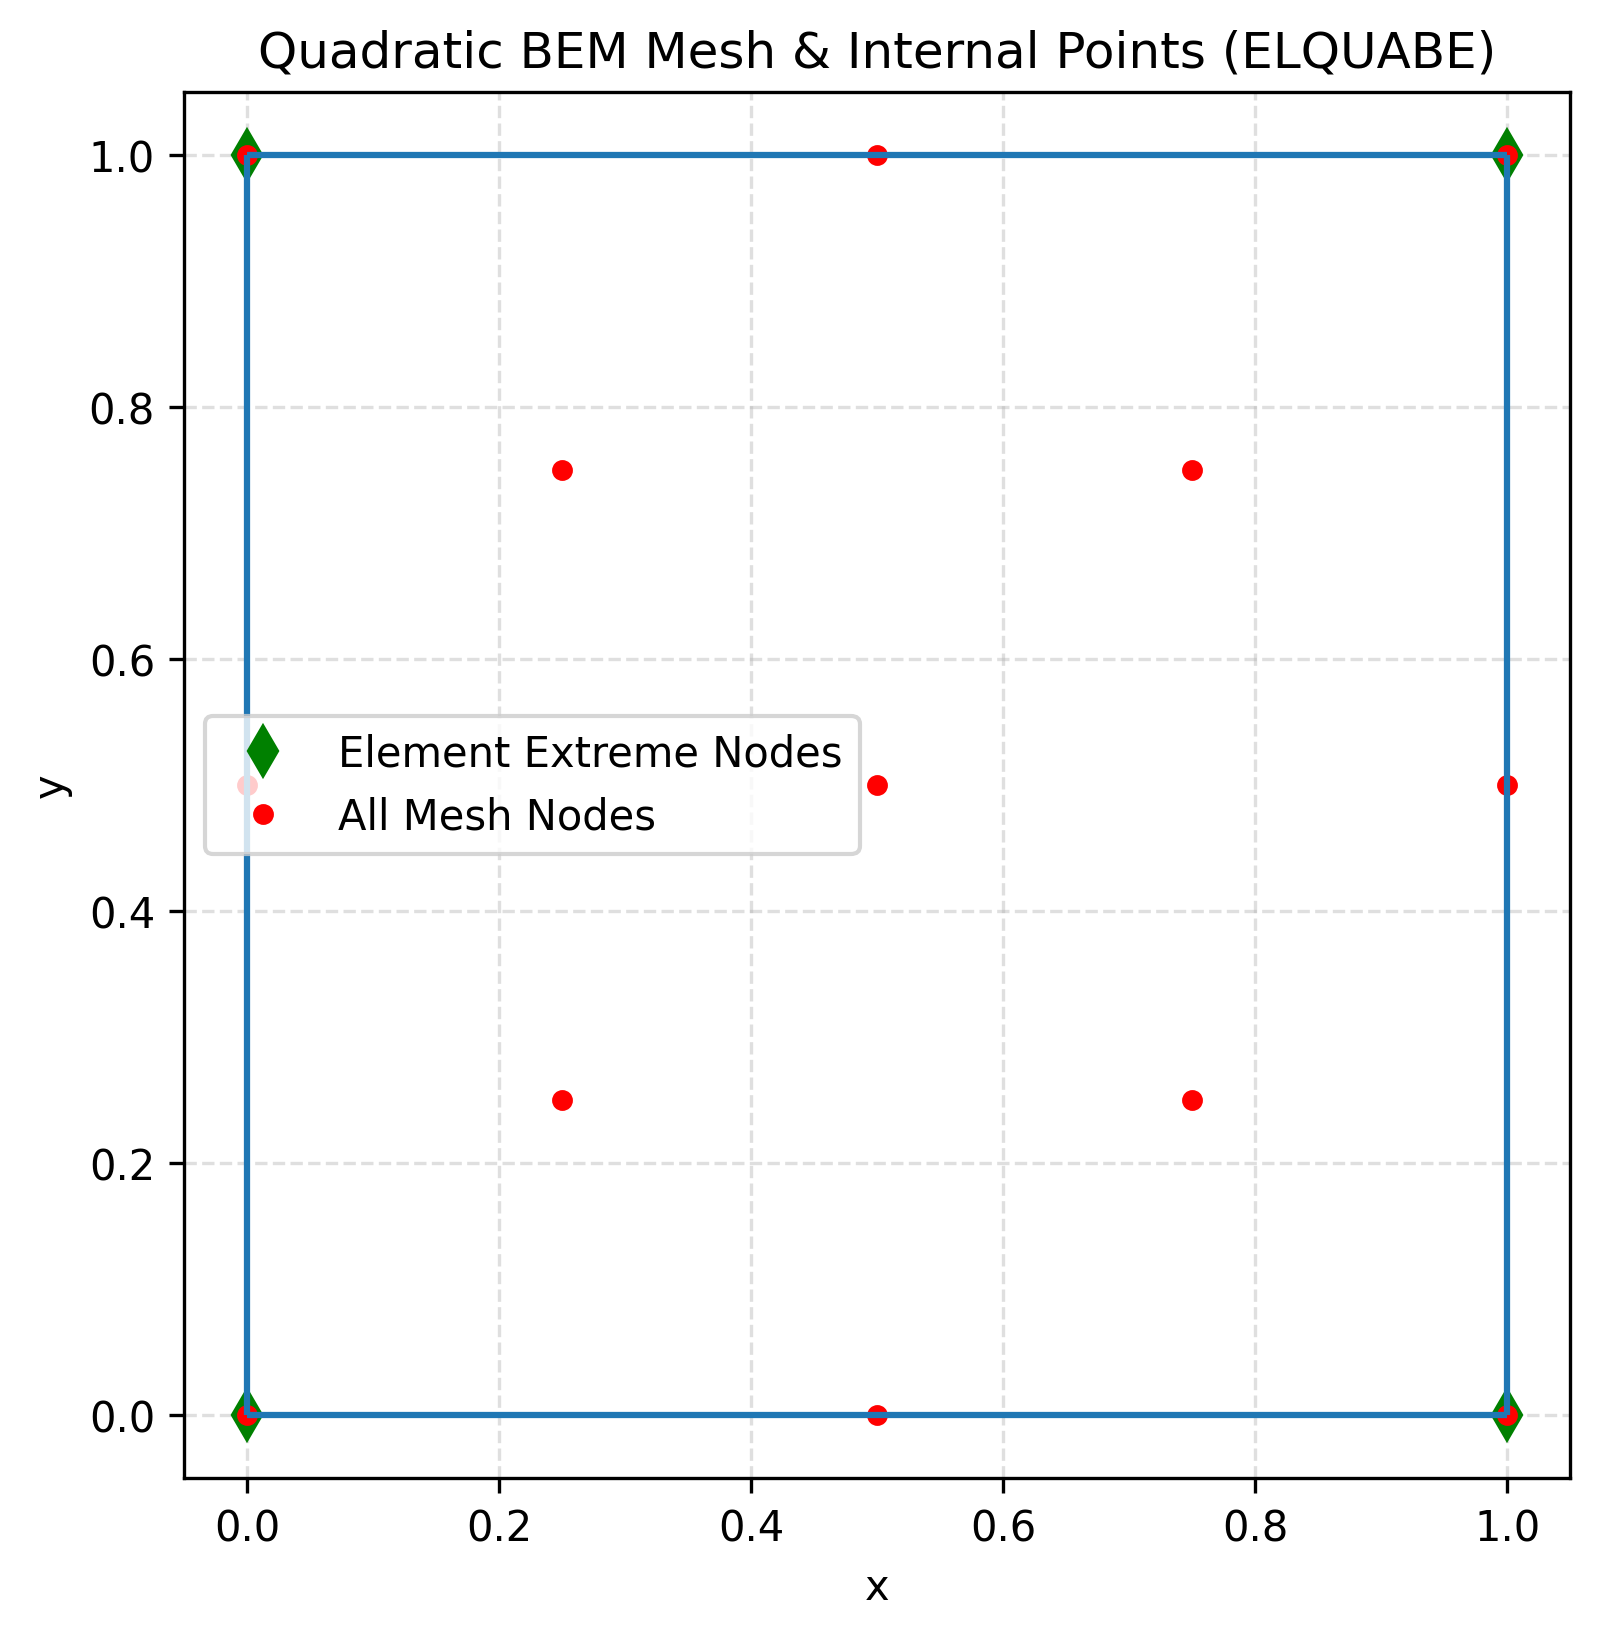

In [12]:
!python preproc.py
from IPython.display import Image, display
display(Image('geometry.png', width=500))

In [13]:
!cat eq12cb.dat

SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)
 4,5,        0.5,0.00
  0.  0.  0.5  0.  1.  0.  1.  0.5  1.  1.  0.5  1.  0.  1.  0.  0.5
0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
1 0.0 1 1.0 1 0.0 1 1.0 1 0.0 1 1.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
 0.5  0.5 0.8  0.2 0.2  0.2 0.2  0.8 0.8  0.8


## 6. Run the Modernized BEM Solver (./elquabe_modern.exe)


In [14]:
!./elquabe_modern.exe
!cat eq12cb.out

 *******************************************************************************
SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)              


  DATA
  NUMBER OF BOUNDARY ELEMENTS=  4
  NUMBER OF INTERNAL POINTS=  5
  SHEAR MODULUS= 0.5000000E+00
  POISSON RATIO= 0.0000000E+00


  BOUNDARY NODES COORDINATES


    NODE          X                  Y

       1      0.0000000E+00      0.0000000E+00
       2      0.5000000E+00      0.0000000E+00
       3      0.1000000E+01      0.0000000E+00
       4      0.1000000E+01      0.5000000E+00
       5      0.1000000E+01      0.1000000E+01
       6      0.5000000E+00      0.1000000E+01
       7      0.0000000E+00      0.1000000E+01
       8      0.0000000E+00      0.5000000E+00


  BOUNDARY CONDITIONS

                                   PRESCRIBED VALUES
       -----FIRST NODE------   -----SECOND NODE-----   -----THIRD NODE------
 ELE   X DIR.  C   Y DIR.  C   X DIR.  C   Y DIR.  C   X DIR.  C   Y DIR.  C

   1    0.000  0   

## 7. Post-Processing & Analytical Validation (posproc.py)


In [15]:
%%writefile posproc.py
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib import cm
import meshio

from preproc import input_data, compute_inodes


def read_elquabe_input(filename='eq12cb.dat'):
    """
    Reads the ELQUABE input file (`eq12cb.dat`) and returns material properties,
    boundary node coordinates, and internal point coordinates.
    """
    with open(filename, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]

    title = lines[0]
    params = lines[1].replace(',', ' ').split()
    ne = int(params[0])
    n_int = int(params[1])
    ge = float(params[2])
    xnu = float(params[3])

    n_bou = 2 * ne
    bou_vals = [float(v) for v in lines[2].split()]
    bou_coords = np.array(bou_vals, dtype=np.float64).reshape((n_bou, 2))

    int_coords = np.zeros((n_int, 2), dtype=np.float64)
    if n_int > 0:
        int_vals = [float(v) for v in lines[3 + ne].split()]
        int_coords = np.array(int_vals, dtype=np.float64).reshape((n_int, 2))

    return {
        'title': title,
        'ne': ne,
        'n_bou': n_bou,
        'n_int': n_int,
        'ge': ge,
        'xnu': xnu,
        'bou_coords': bou_coords,
        'int_coords': int_coords,
    }


def read_elquabe_outputs():
    """
    Reads numerical results exported by ELQUABE:
      - `dpbou.dat`: Boundary displacements (ux, uy, |u|)
      - `dpint.dat`: Internal displacements (ux, uy, |u|)
      - `stbou.dat`: Boundary tractions (tx, ty)
      - `stint.dat`: Internal stresses (sigma_x, tau_xy, sigma_y)
    """
    dpbou = np.loadtxt('dpbou.dat')
    dpint = np.loadtxt('dpint.dat')
    stbou = np.loadtxt('stbou.dat')
    stint = np.loadtxt('stint.dat')
    return {
        'dpbou': dpbou,
        'dpint': dpint,
        'stbou': stbou,
        'stint': stint,
    }


def compute_analytical_solution(coords, ge, xnu, traction_y=1.0):
    """
    Computes the analytical 2D plane-strain elastostatic solution for a plate
    fixed at y = 0 and subjected to uniform vertical traction sigma_y = traction_y
    at the top edge:
        E' = 2 * G / (1 - nu)
        u_y(y) = (traction_y / E') * y
        sigma_x = 0, tau_xy = 0, sigma_y = traction_y
    """
    e_plane_strain = 2.0 * ge / (1.0 - xnu)
    y = coords[:, 1]
    uy_exact = (traction_y / e_plane_strain) * y
    sigma_y_exact = np.full_like(y, traction_y)
    sigma_x_exact = np.zeros_like(y)
    tau_xy_exact = np.zeros_like(y)
    return {
        'uy': uy_exact,
        'sigma_x': sigma_x_exact,
        'tau_xy': tau_xy_exact,
        'sigma_y': sigma_y_exact,
    }


def plot_validation(inp, out, save_path='result_plot.png'):
    """
    Compares numerical BEM displacements and stresses against the analytical
    2D elastostatic solution and saves the plot to `result_plot.png`.
    """
    bou_coords = inp['bou_coords']
    int_coords = inp['int_coords']
    ge = inp['ge']
    xnu = inp['xnu']

    dpbou = out['dpbou']
    dpint = out['dpint']
    stint = out['stint']

    y_cont = np.linspace(0.0, np.max(bou_coords[:, 1]), 100)
    cont_coords = np.column_stack([np.full_like(y_cont, 0.5), y_cont])
    exact_cont = compute_analytical_solution(cont_coords, ge, xnu, traction_y=1.0)

    exact_bou = compute_analytical_solution(bou_coords, ge, xnu, traction_y=1.0)
    exact_int = compute_analytical_solution(int_coords, ge, xnu, traction_y=1.0)

    # Compute relative L2 errors
    all_uy_num = np.concatenate([dpbou[:, 1], dpint[:, 1]])
    all_uy_ex = np.concatenate([exact_bou['uy'], exact_int['uy']])
    err_uy = np.linalg.norm(all_uy_num - all_uy_ex) / np.linalg.norm(all_uy_ex)
    err_sy = np.linalg.norm(stint[:, 2] - exact_int['sigma_y']) / np.linalg.norm(exact_int['sigma_y'])

    print("=" * 72)
    print("ELQUABE 2D ELASTOSTATIC VALIDATION SUMMARY")
    print("=" * 72)
    print(f"Relative L2 Error in Vertical Displacement u_y : {err_uy:.4e}")
    print(f"Relative L2 Error in Vertical Stress sigma_y   : {err_sy:.4e}")
    print("-" * 72)
    print("Internal Points Comparison (y, u_y_num, u_y_exact, sigma_y_num, sigma_y_exact):")
    for k in range(inp['n_int']):
        print(
            f"  Point {k+1} ({int_coords[k,0]:.2f}, {int_coords[k,1]:.2f}): "
            f"u_y = {dpint[k,1]:.6f} (exact: {exact_int['uy'][k]:.6f}) | "
            f"sigma_y = {stint[k,2]:.6f} (exact: {exact_int['sigma_y'][k]:.6f})"
        )
    print("=" * 72)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Left subplot: Vertical displacement u_y vs y
    ax1.plot(y_cont, exact_cont['uy'], 'r-', linewidth=2, label='Analytical Solution $u_y(y)$')
    ax1.plot(bou_coords[:, 1], dpbou[:, 1], 'bo', markersize=7, label='BEM Boundary Nodes')
    ax1.plot(int_coords[:, 1], dpint[:, 1], 'gs', markersize=7, label='BEM Internal Points')
    ax1.set_xlabel('Vertical Coordinate $y$ (m)')
    ax1.set_ylabel('Vertical Displacement $u_y$ (m)')
    ax1.set_title('Vertical Displacement $u_y$ vs. $y$')
    ax1.legend(loc='best')
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Right subplot: Internal stresses vs y
    ax2.plot(y_cont, exact_cont['sigma_y'], 'r-', linewidth=2, label='Analytical $\\sigma_y = 1.0$')
    ax2.plot(y_cont, exact_cont['sigma_x'], 'k--', linewidth=1.5, label='Analytical $\\sigma_x = \\tau_{xy} = 0.0$')
    ax2.plot(int_coords[:, 1], stint[:, 2], 'bs', markersize=7, label='BEM $\\sigma_y$')
    ax2.plot(int_coords[:, 1], stint[:, 0], 'go', markersize=6, label='BEM $\\sigma_x$')
    ax2.plot(int_coords[:, 1], stint[:, 1], 'm^', markersize=6, label='BEM $\\tau_{xy}$')
    ax2.set_xlabel('Vertical Coordinate $y$ (m)')
    ax2.set_ylabel('Stress Components (Pa)')
    ax2.set_title('Internal Point Stresses vs. $y$')
    ax2.set_ylim(-0.2, 1.2)
    ax2.legend(loc='best')
    ax2.grid(True, linestyle='--', alpha=0.5)

    fig.suptitle('ELQUABE 2D Elastostatic Validation: Analytical vs. BEM', fontsize=13)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Validation plot saved to '{save_path}'.")
    plt.close(fig)


def export_vtk_and_contour(out, vtk_path='resultado_elquabe.vtk', png_path='displacement_map.png'):
    """
    Maps the BEM boundary and internal displacements back onto the Gmsh quadratic
    triangle mesh (`placa.msh`), exports a VTK file, and plots the 2D contour map.
    """
    inp_params = input_data()
    computed_data = compute_inodes(inp_params['file_name'], inp_params['bound_cond'])

    coord = computed_data['coordinates']
    elements = computed_data['elements']
    tri6 = computed_data['triangles']
    int_nodes = computed_data['internal_nodes']

    n_total = coord.shape[0]
    disp_vec = np.zeros((n_total, 3), dtype=np.float64)
    uy_field = np.zeros(n_total, dtype=np.float64)

    # Map boundary node displacements in the same order written by preproc.py
    dpbou = out['dpbou']
    bou_idx = 0
    for elem in elements:
        for node_id in (elem[0], elem[2]):
            disp_vec[node_id, 0] = dpbou[bou_idx, 0]
            disp_vec[node_id, 1] = dpbou[bou_idx, 1]
            uy_field[node_id] = dpbou[bou_idx, 1]
            bou_idx += 1

    # Map internal node displacements
    dpint = out['dpint']
    for k, node_id in enumerate(int_nodes):
        disp_vec[node_id, 0] = dpint[k, 0]
        disp_vec[node_id, 1] = dpint[k, 1]
        uy_field[node_id] = dpint[k, 1]

    # 1. Export VTK with quadratic triangle6 elements
    cells = [('triangle6', tri6)]
    mesh_out = meshio.Mesh(
        coord,
        cells,
        point_data={
            'Displacement_Y': uy_field,
            'Displacement': disp_vec,
        },
    )
    meshio.write(vtk_path, mesh_out)
    print(f"VTK file '{vtk_path}' saved successfully.")

    # 2. Subdivide each 6-node triangle into 4 linear triangles for Matplotlib contour plot
    tri3_list = []
    for t in tri6:
        v0, v1, v2, v3, v4, v5 = t
        tri3_list.append([v0, v3, v5])
        tri3_list.append([v3, v1, v4])
        tri3_list.append([v5, v4, v2])
        tri3_list.append([v3, v4, v5])

    tri3_array = np.array(tri3_list)

    fig, ax = plt.subplots(figsize=(6, 5))
    triang = mtri.Triangulation(coord[:, 0], coord[:, 1], tri3_array)

    ax.triplot(triang, color=(0.0, 0.0, 0.0), linewidth=0.4)
    contourf = ax.tricontourf(triang, uy_field, levels=20, cmap=cm.jet)
    fig.colorbar(contourf, ax=ax, label='Vertical Displacement $u_y$ (m)')

    ax.set_title('Vertical Displacement $u_y$ Contour (Quadratic Elements)')
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_aspect('equal')

    plt.savefig(png_path, dpi=300, bbox_inches='tight')
    print(f"Contour map '{png_path}' saved successfully.")
    plt.close(fig)


if __name__ == '__main__':
    inp = read_elquabe_input('eq12cb.dat')
    out = read_elquabe_outputs()
    plot_validation(inp, out, save_path='result_plot.png')
    if os.path.exists('placa.msh') or os.path.exists('placa.geo'):
        export_vtk_and_contour(out)

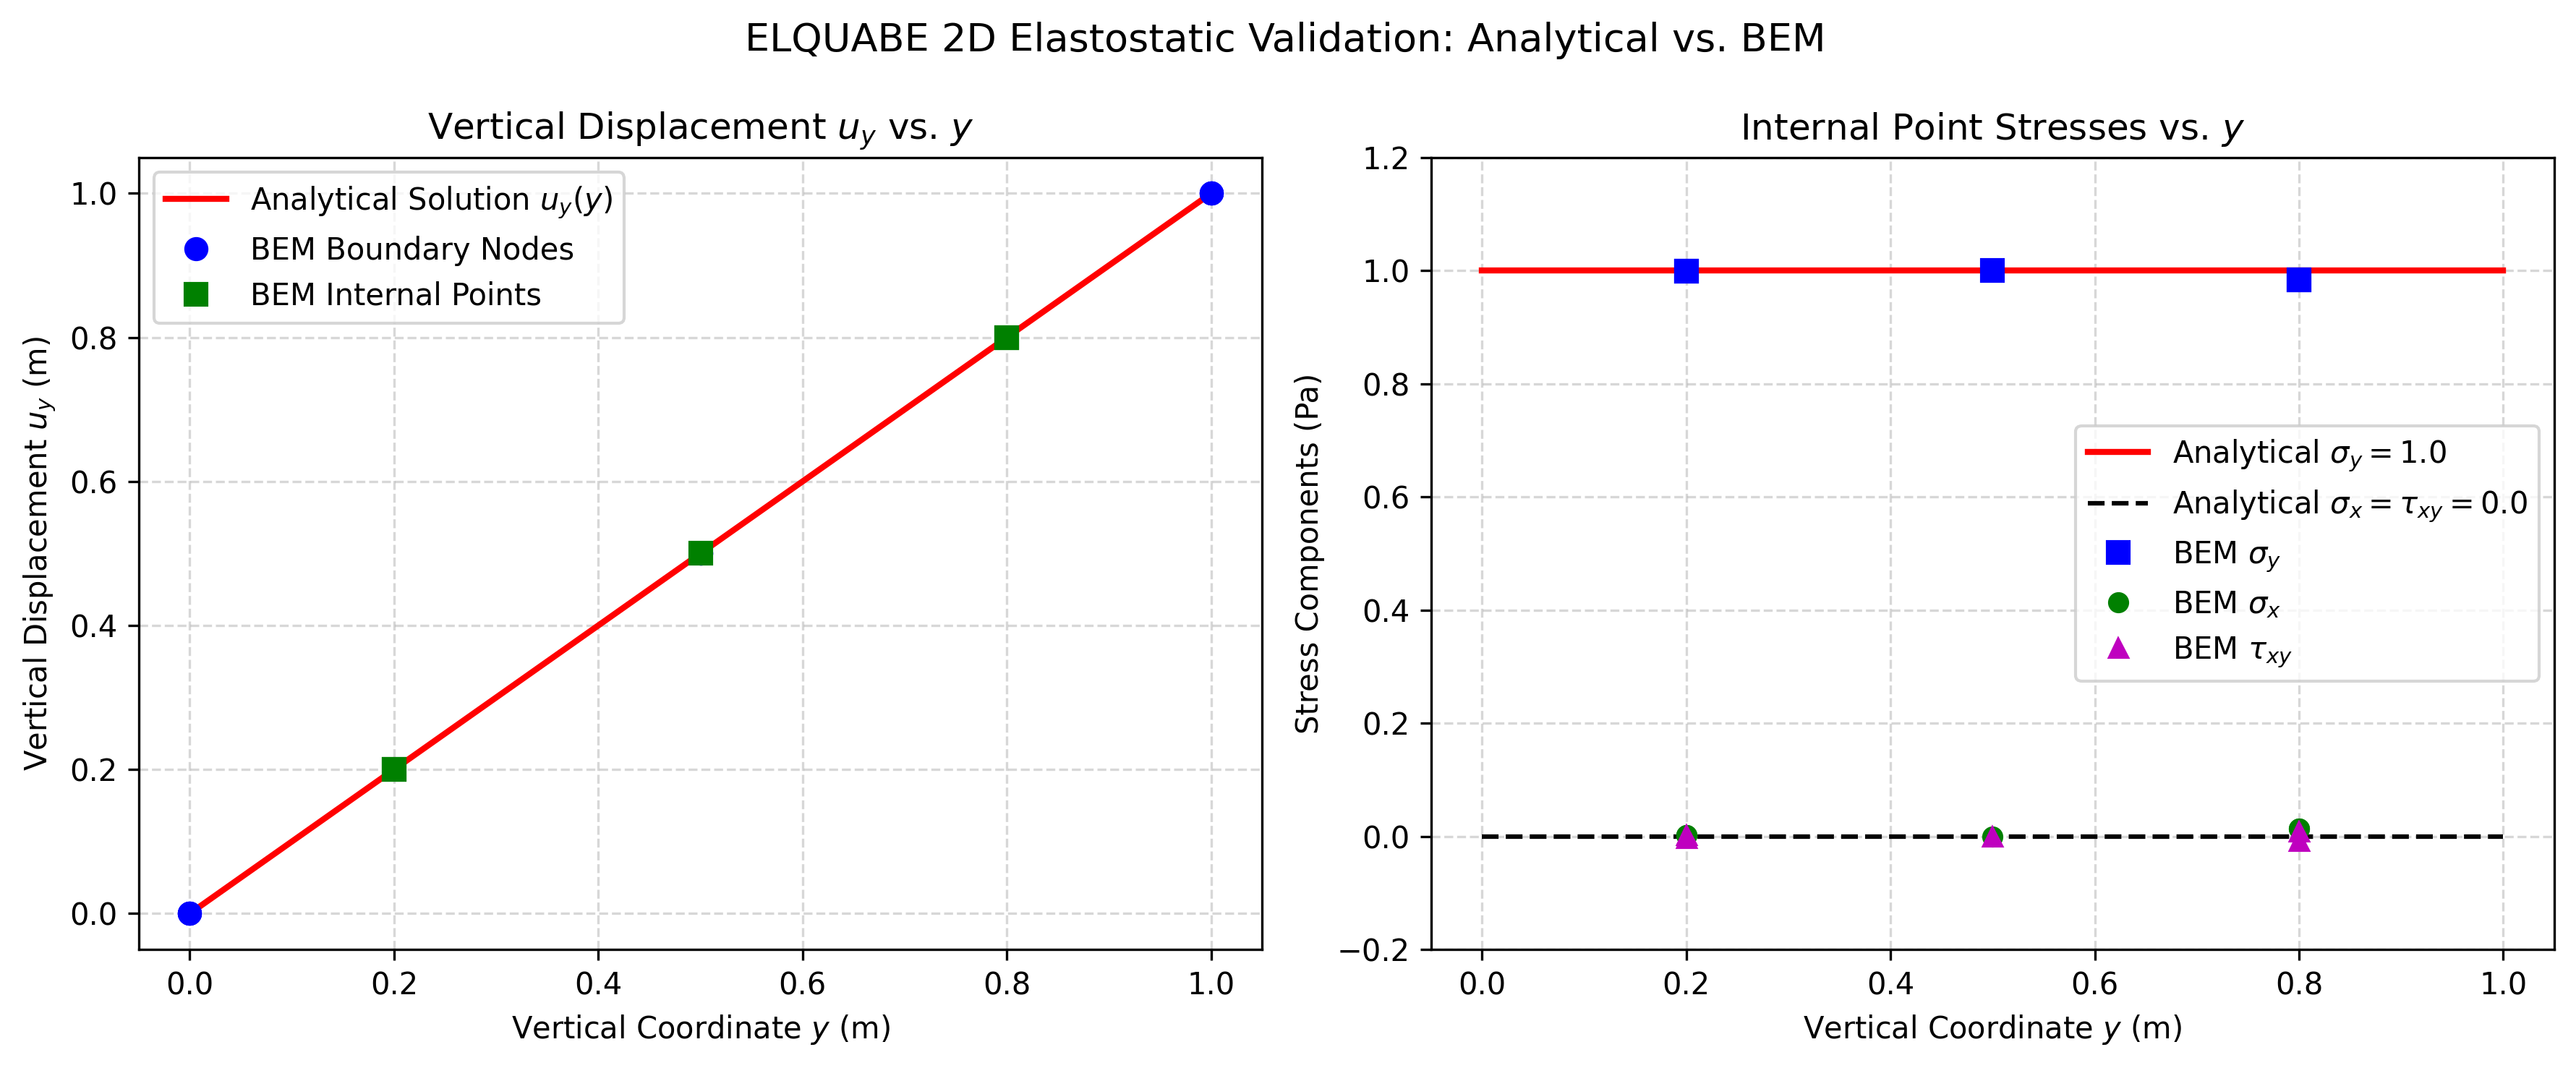

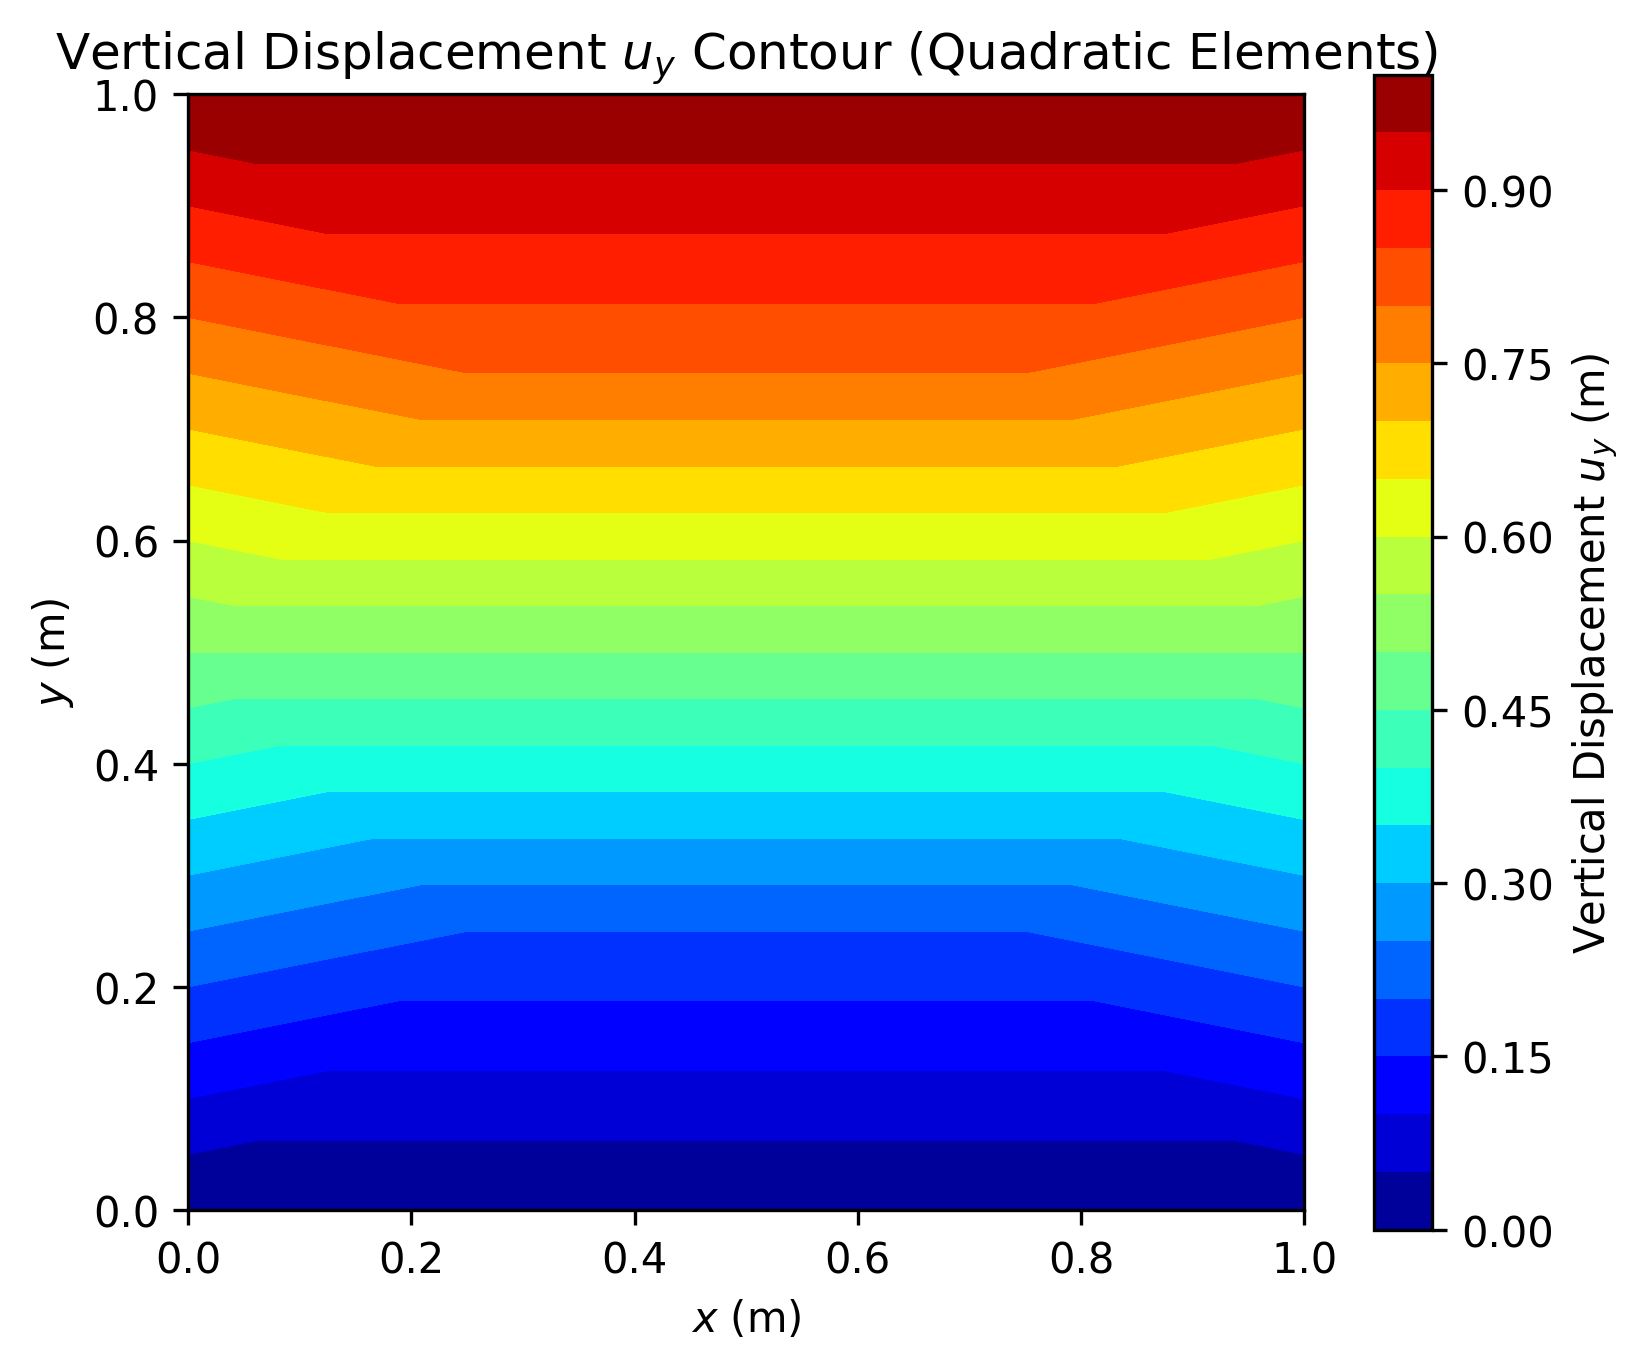

In [16]:
!python posproc.py
from IPython.display import Image, display
display(Image('result_plot.png', width=850))
display(Image('displacement_map.png', width=500))